### **00. Import Libs and the DataSet**

In [1]:
#Import Libs
import pandas as pd
import numpy as np
import time

In [2]:
#Import Specific Libs
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold, ShuffleSplit,
                                     StratifiedShuffleSplit, LeaveOneOut, GroupKFold, GroupShuffleSplit, StratifiedGroupKFold,
                                     TimeSeriesSplit, cross_val_score, cross_val_predict, cross_validate, learning_curve, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef)
from scipy import stats
from IPython.display import display

In [3]:
#Import the Graphic Libs
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Ignore Error Message
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
#Import Dataframe from Github
df = pd.read_csv('https://raw.githubusercontent.com/jrafa1607/DataScience-ML-AI/main/-%20Datasets/credit_data.csv')

In [6]:
#Define New Attributes Names
df.columns = ['id', 'income', 'age', 'loan', 'result']
df.head(3)

,id,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [7]:
#Fix the Invalid Values ( Negative Ages Become Null: the Imputer Inside the Model Fills Them Without Leakage )
df.loc[df['age'] < 0, 'age'] = np.nan
print(df.isnull().sum())

id        0
income    0
age       6
loan      0
result    0
dtype: int64


In [8]:
#Split the Dataframe in Data (X) and Classifier (Y)
X = df[['income', 'age', 'loan']]
y = df['result']
print(X.shape, y.shape)

(2000, 3) (2000,)


In [9]:
#Create the Model Used to Evaluate the Splits ( Imputer and Scaler Inside the Pipeline = Fitted Only on the Train Data )
def make_model():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))

In [10]:
#Create the Function that Summarizes a Split
def split_summary(y_train, y_test):
    total = len(y_train) + len(y_test)
    return pd.DataFrame({'rows': [len(y_train), len(y_test)],
                         'rows_%': [len(y_train) / total * 100, len(y_test) / total * 100],
                         'positive_rows': [int(y_train.sum()), int(y_test.sum())],
                         'positive_%': [y_train.mean() * 100, y_test.mean() * 100]}, index=['train', 'test']).round(2)

### **01. Hold-out Split ( Train and Test )**

The simplest way: the data is divided **once** in two parts. The model learns with the train set and is evaluated with the test set, that it has never seen.

| Parameter | What it does |
|---|---|
| `test_size` / `train_size` | Share ( or number of rows ) of each part |
| `random_state` | Fixes the shuffle: the same number gives the same split |
| `shuffle` | Shuffle the rows before the split ( default `True` ) |
| `stratify` | Keeps the class proportion in both parts |

In [11]:
#Apply the Train Test Split by Sklearn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [12]:
#Show the Size of Data (X)
print(X_train.shape, X_test.shape)

(1500, 3) (500, 3)


In [13]:
#Show the Size of Classifier (Y)
print(y_train.shape, y_test.shape)

(1500,) (500,)


In [14]:
#Metrics ( Size and Share of Defaults in Each Part )
split_summary(y_train, y_test)

,rows,rows_%,positive_rows,positive_%
train,1500,75.0,219,14.6
test,500,25.0,64,12.8


In [15]:
#Different Test Sizes
rows = []
for test_size in [0.10, 0.20, 0.25, 0.30, 0.40, 0.50]:
    _, X_te, _, y_te = train_test_split(X, y, test_size=test_size, random_state=0)
    rows.append({'test_size': test_size, 'train_rows': len(X) - len(X_te), 'test_rows': len(X_te), 'positives_in_test': int(y_te.sum())})
pd.DataFrame(rows)

,test_size,train_rows,test_rows,positives_in_test
0,0.10,1800,200,28
1,0.20,1600,400,52
2,0.25,1500,500,64
3,0.30,1400,600,76
4,0.40,1200,800,110
5,0.50,1000,1000,136


In [16]:
#Reproducibility ( random_state )
same_a = train_test_split(X, y, test_size=0.25, random_state=0)[1].index
same_b = train_test_split(X, y, test_size=0.25, random_state=0)[1].index
other_a = train_test_split(X, y, test_size=0.25)[1].index
other_b = train_test_split(X, y, test_size=0.25)[1].index

#Metrics ( Same Test Rows? )
print('random_state=0 twice  -> identical test set:', same_a.equals(same_b))
print('random_state=None twice -> identical test set:', other_a.equals(other_b))

random_state=0 twice  -> identical test set: True
random_state=None twice -> identical test set: False


### **02. Stratified Split**

When one class is rare ( here, only about 14% of the clients default ), a random split can put **too many or too few** rare cases in the test set. With `stratify=y` both parts keep the same class proportion.

In [17]:
#Apply the Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
split_summary(y_train, y_test)

,rows,rows_%,positive_rows,positive_%
train,1500,75.0,212,14.13
test,500,25.0,71,14.20


In [18]:
#Compare the Positive Rate of the Test Set in 200 Different Seeds ( Random vs Stratified )
rates = {'random': [], 'stratified': []}
for seed in range(200):
    rates['random'].append(train_test_split(X, y, test_size=0.25, random_state=seed)[3].mean() * 100)
    rates['stratified'].append(train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)[3].mean() * 100)
rates = pd.DataFrame(rates)

#Metrics ( How Far the Test Set Can Be from the Real Positive Rate )
print('Real positive rate (%):', round(y.mean() * 100, 2))
rates.describe().round(3)

Real positive rate (%): 14.15


,random,stratified
count,200.000,200.0
mean,14.193,14.2
std,1.365,0.0
min,10.800,14.2
25%,13.200,14.2
50%,14.200,14.2
75%,15.200,14.2
max,18.400,14.2


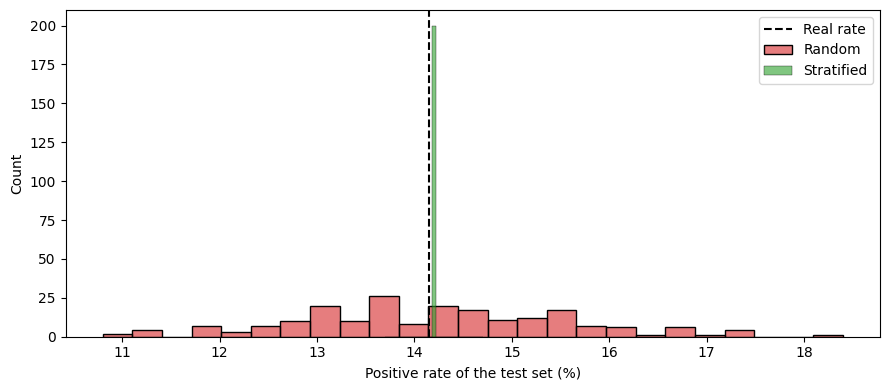

In [19]:
#Chart of the Positive Rate of the Test Set
plt.figure(figsize=(9, 4))
sns.histplot(rates['random'], color='tab:red', label='Random', bins=25, alpha=0.6)
sns.histplot(rates['stratified'], color='tab:green', label='Stratified', bins=25, alpha=0.6)
plt.axvline(y.mean() * 100, color='black', linestyle='--', label='Real rate')
plt.xlabel('Positive rate of the test set (%)')
plt.legend()
plt.tight_layout()
plt.show()

### **03. Train, Validation and Test**

The **validation** set is used to choose the model and its parameters. The **test** set is used **only once**, at the end, to estimate the real performance. Two calls of `train_test_split` create the three parts.

In [20]:
#Split in Train + Validation ( 80% ) and Test ( 20% )
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=0, stratify=y)

In [21]:
#Split the 80% in Train ( 60% ) and Validation ( 20% )
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=0, stratify=y_temp)    # 25% of 80% = 20%

In [22]:
#Metrics ( Size, Class Proportion and Overlap Between the Parts )
summary = pd.DataFrame({'rows': [len(y_train), len(y_val), len(y_test)],
                        'rows_%': [len(y_train) / len(y) * 100, len(y_val) / len(y) * 100, len(y_test) / len(y) * 100],
                        'positive_%': [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100]}, index=['train', 'validation', 'test']).round(2)
print(summary)
print('\nRows in more than one part:', len(set(X_train.index) & set(X_val.index)) + len(set(X_train.index) & set(X_test.index)) + len(set(X_val.index) & set(X_test.index)))
print('Total rows kept:', len(y_train) + len(y_val) + len(y_test) == len(y))

            rows  rows_%  positive_%
train       1200    60.0       14.08
validation   400    20.0       14.25
test         400    20.0       14.25

Rows in more than one part: 0
Total rows kept: True


### **04. Ordered Split ( No Shuffle )**

If the rows have a **time order** ( the oldest rows first ) a random split lets the model "see the future". With `shuffle=False` the first rows go to train and the last rows go to test. This dataset has no date, so the order of the `id` is used as the time order.

In [23]:
#Apply the Split Without Shuffle ( First 75% to Train, Last 25% to Test )
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, shuffle=False)
print('Last train id:', df.loc[X_train.index[-1], 'id'], '| First test id:', df.loc[X_test.index[0], 'id'])
split_summary(y_train, y_test)

Last train id: 1500 | First test id: 1501


,rows,rows_%,positive_rows,positive_%
train,1500,75.0,215,14.33
test,500,25.0,68,13.60


In [24]:
#Metrics ( Did the Data Change Between the Past and the Future? KS Test per Attribute )
drift = pd.DataFrame({col: {'mean_train': X_train[col].mean(), 'mean_test': X_test[col].mean(),
                            'KS_statistic': stats.ks_2samp(X_train[col].dropna(), X_test[col].dropna()).statistic,
                            'KS_pvalue': stats.ks_2samp(X_train[col].dropna(), X_test[col].dropna()).pvalue} for col in X.columns}).T
print(drift.round(4))
print('\n( p-value < 0.05 = the test data is different from the train data: drift )')

        mean_train   mean_test  KS_statistic  KS_pvalue
income  45082.8047  46077.9860        0.0527     0.2451
age        41.1925     40.1365        0.0629     0.0977
loan     4385.1875   4621.9161        0.0700     0.0495

( p-value < 0.05 = the test data is different from the train data: drift )


### **05. Group Split ( Avoid Leakage )**

When several rows belong to the **same entity** ( the same client, patient, household ), they must stay together. If one row goes to train and another row of the same entity goes to test, the model "recognizes" the entity and the score is too optimistic.

This dataset has one row per client, so a **synthetic group** is created only to show the problem: clients of the same household.

In [25]:
#Create a Group Attribute ( Synthetic Example: Household of the Client )
groups = pd.Series(np.random.default_rng(0).integers(0, 600, size=len(df)), index=df.index, name='household_id')
print('Households:', groups.nunique(), '| Average clients per household:', round(len(groups) / groups.nunique(), 2))

Households: 574 | Average clients per household: 3.48


In [26]:
#Random Split ( Ignores the Groups )
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(X, y, groups, test_size=0.25, random_state=0)

#Metrics ( Households in Both Train and Test = Leakage )
print('Households in train AND test:', len(set(g_train) & set(g_test)), 'of', g_test.nunique(), 'households of the test set')

Households in train AND test: 294 of 327 households of the test set


In [27]:
#Group Split ( Each Group Goes Entirely to Train or to Test )
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]

#Metrics ( Leakage and Size of the Parts )
print('Households in train AND test:', len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
split_summary(y_train, y_test)

Households in train AND test: 0


,rows,rows_%,positive_rows,positive_%
train,1499,74.95,224,14.94
test,501,25.05,59,11.78


In [28]:
#Group Split with Stratification ( StratifiedGroupKFold: Keeps the Groups Together and the Class Proportion )
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
rows = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups)):
    rows.append({'fold': fold, 'test_rows': len(test_idx), 'test_positive_%': y.iloc[test_idx].mean() * 100,
                 'shared_groups': len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))})
pd.DataFrame(rows).round(2)

,fold,test_rows,test_positive_%,shared_groups
0,0,504,13.10,0
1,1,500,16.00,0
2,2,492,14.23,0
3,3,504,13.29,0


### **06. Cross-Validation Strategies**

With a single hold-out the result depends on **which rows** went to the test set. Cross-validation repeats the split several times and uses all the rows to train and to test.

| Strategy | How it works | When to use |
|---|---|---|
| `KFold` | k parts, each one is the test once | Balanced classes, regression |
| `StratifiedKFold` | `KFold` keeping the class proportion | **Classification, mainly with rare classes** |
| `RepeatedStratifiedKFold` | `StratifiedKFold` repeated with different shuffles | Small datasets, more stable estimate |
| `ShuffleSplit` / `StratifiedShuffleSplit` | Several random splits with a chosen test size | Control the size of the test set |
| `LeaveOneOut` | Each row is the test once | Very small datasets ( slow ) |
| `GroupKFold` / `StratifiedGroupKFold` | Groups stay together | Several rows per entity |
| `TimeSeriesSplit` | Train always before test | Data with time order |
| Bootstrap | Sample with replacement, test with the rows left out ( out-of-bag ) | Estimate the uncertainty |

In [29]:
#Create the Function that Shows the Folds of a Strategy
def fold_summary(cv, X, y, groups=None):
    rows = []
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups)):
        rows.append({'fold': fold, 'train_rows': len(train_idx), 'test_rows': len(test_idx), 'test_positive_%': y.iloc[test_idx].mean() * 100,
                     'shared_groups': len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])) if groups is not None else np.nan})
    return pd.DataFrame(rows).round(2)

In [30]:
#K-Fold ( 5 Parts, Shuffled )
fold_summary(KFold(n_splits=5, shuffle=True, random_state=0), X, y)

,fold,train_rows,test_rows,test_positive_%,shared_groups
0,0,1600,400,13.00,NaN
1,1,1600,400,14.50,NaN
2,2,1600,400,13.00,NaN
3,3,1600,400,15.25,NaN
4,4,1600,400,15.00,NaN


In [31]:
#Stratified K-Fold ( 5 Parts, the Same Class Proportion in All of Them )
fold_summary(StratifiedKFold(n_splits=5, shuffle=True, random_state=0), X, y)

,fold,train_rows,test_rows,test_positive_%,shared_groups
0,0,1600,400,14.00,NaN
1,1,1600,400,14.00,NaN
2,2,1600,400,14.25,NaN
3,3,1600,400,14.25,NaN
4,4,1600,400,14.25,NaN


In [32]:
#Create the Strategies Used in the Next Examples
strategies = {'KFold (5)': KFold(n_splits=5, shuffle=True, random_state=0),
              'StratifiedKFold (5)': StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
              'RepeatedStratifiedKFold (5x3)': RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0),
              'ShuffleSplit (10 x 25%)': ShuffleSplit(n_splits=10, test_size=0.25, random_state=0),
              'StratifiedShuffleSplit (10 x 25%)': StratifiedShuffleSplit(n_splits=10, test_size=0.25, random_state=0),
              'StratifiedGroupKFold (5)': StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0),
              'TimeSeriesSplit (5)': TimeSeriesSplit(n_splits=5)}
group_strategies = ['StratifiedGroupKFold (5)']

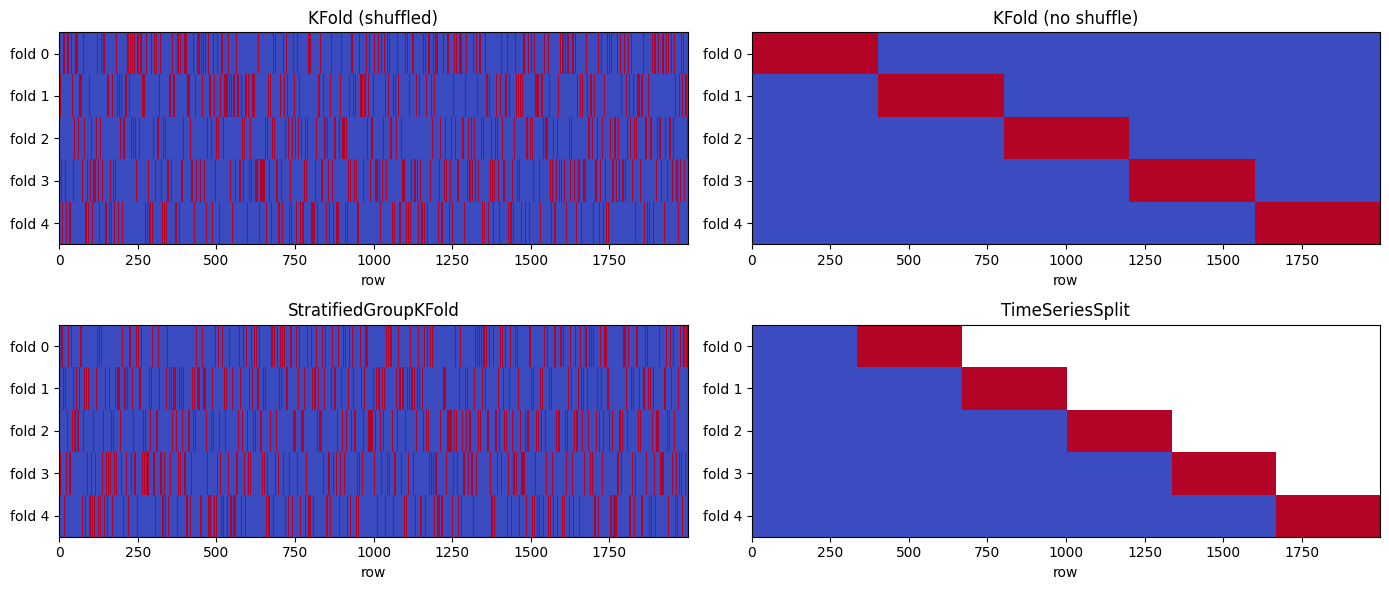

In [33]:
#Visualize How Each Strategy Splits the Data ( Blue = Train, Red = Test, White = Not Used )
def plot_splits(cv, ax, title, groups=None, n_folds=5):
    matrix = np.full((n_folds, len(X)), np.nan)
    for fold, (train_idx, test_idx) in enumerate(list(cv.split(X, y, groups))[:n_folds]):
        matrix[fold, train_idx] = 0
        matrix[fold, test_idx] = 1
    ax.imshow(matrix, aspect='auto', cmap='coolwarm', interpolation='nearest', vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_yticks(range(n_folds))
    ax.set_yticklabels([f'fold {i}' for i in range(n_folds)])
    ax.set_xlabel('row')

fig, axes = plt.subplots(2, 2, figsize=(14, 6))
plot_splits(strategies['KFold (5)'], axes[0, 0], 'KFold (shuffled)')
plot_splits(KFold(n_splits=5), axes[0, 1], 'KFold (no shuffle)')
plot_splits(strategies['StratifiedGroupKFold (5)'], axes[1, 0], 'StratifiedGroupKFold', groups=groups)
plot_splits(strategies['TimeSeriesSplit (5)'], axes[1, 1], 'TimeSeriesSplit')
plt.tight_layout()
plt.show()

In [34]:
#Metrics of the Time Series Split ( Train Always Before the Test )
fold_summary(TimeSeriesSplit(n_splits=5), X, y)

,fold,train_rows,test_rows,test_positive_%,shared_groups
0,0,335,333,14.71,NaN
1,1,668,333,14.71,NaN
2,2,1001,333,14.11,NaN
3,3,1334,333,13.21,NaN
4,4,1667,333,12.91,NaN


In [35]:
#Leave-One-Out ( 2,000 Models, One per Row: Slow! Only Accuracy Makes Sense Because Each Test Has One Row )
start = time.time()
loo_scores = cross_val_score(make_model(), X, y, cv=LeaveOneOut(), scoring='accuracy')
print('Models trained:', len(loo_scores), '| Accuracy:', round(loo_scores.mean(), 4), '| Time (s):', round(time.time() - start, 1))

Models trained: 2000 | Accuracy: 0.946 | Time (s): 68.5


In [36]:
#Bootstrap ( Train with a Sample with Replacement, Test with the Rows that Were Left Out )
def bootstrap_oob_scores(model_factory, X, y, n_rounds=50, seed=0):
    rng = np.random.default_rng(seed)
    scores, oob_share = [], []
    for _ in range(n_rounds):
        sample = rng.integers(0, len(X), len(X))
        out_of_bag = np.setdiff1d(np.arange(len(X)), sample)
        model = model_factory().fit(X.iloc[sample], y.iloc[sample])
        scores.append(roc_auc_score(y.iloc[out_of_bag], model.predict_proba(X.iloc[out_of_bag])[:, 1]))
        oob_share.append(len(out_of_bag) / len(X))
    return np.array(scores), np.mean(oob_share)

#Metrics ( AUC Distribution and Share of Rows Left Out: Expected 36.8% )
scores, oob_share = bootstrap_oob_scores(make_model, X, y)
print('Out-of-bag share:', round(oob_share * 100, 1), '% | AUC mean:', round(scores.mean(), 4), '| std:', round(scores.std(ddof=1), 4), '| 95% interval:', np.percentile(scores, [2.5, 97.5]).round(4))

Out-of-bag share: 36.9 % | AUC mean: 0.9839 | std: 0.003 | 95% interval: [0.978  0.9885]


### **07. Metrics to Evaluate the Quality of a Split**

A good split makes the **test set look like the train set** ( and like the future data ). These metrics measure it **before** training any model:

| Metric | What it measures | Ideal | Rule of thumb |
|---|---|---|---|
| Class gap | Difference between the positive rate of train and test ( percentage points ) | 0 | < 2 pp |
| KS statistic | Largest difference between the distributions of train and test, per attribute | 0 | p-value > 0.05 |
| SMD | Standardized mean difference between train and test, per attribute | 0 | abs( SMD ) < 0.10 |
| PSI | Population Stability Index: how much the distribution of an attribute moved | 0 | < 0.10 stable, > 0.25 big change |
| Adversarial AUC | AUC of a model that tries to tell if a row is from train or from test | 0.5 | < 0.60 |
| Duplicated rows in both | Identical rows in train and test ( leakage ) | 0 | 0 |

In [37]:
#Define the Standardized Mean Difference ( SMD )
def smd(train_col, test_col):
    pooled_std = np.sqrt((train_col.var() + test_col.var()) / 2)
    return (test_col.mean() - train_col.mean()) / pooled_std

In [38]:
#Define the Population Stability Index ( PSI )
def psi(train_col, test_col, bins=10):
    train_col, test_col = train_col.dropna(), test_col.dropna()
    edges = np.unique(np.quantile(train_col, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    expected = np.clip(np.histogram(train_col, edges)[0] / len(train_col), 1e-4, None)
    actual = np.clip(np.histogram(test_col, edges)[0] / len(test_col), 1e-4, None)
    return np.sum((actual - expected) * np.log(actual / expected))

In [39]:
#Define the Adversarial Validation ( Can a Model Tell Train from Test? )
def adversarial_auc(X_train, X_test, seed=0):
    data = pd.concat([X_train, X_test])
    label = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
    model = make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=seed, n_jobs=-1))
    proba = cross_val_predict(model, data, label, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba')[:, 1]
    return roc_auc_score(label, proba)

In [40]:
#Define the Split Report ( All the Metrics of a Split in One Row )
def split_report(X_train, X_test, y_train, y_test, name='split'):
    ks = {col: stats.ks_2samp(X_train[col].dropna(), X_test[col].dropna()) for col in X_train.columns}
    class_table = pd.crosstab(np.r_[np.zeros(len(y_train)), np.ones(len(y_test))], np.r_[y_train, y_test])
    shared_rows = len(set(pd.util.hash_pandas_object(X_train, index=False)) & set(pd.util.hash_pandas_object(X_test, index=False)))
    report = {'train_rows': len(X_train), 'test_rows': len(X_test), 'test_%': len(X_test) / (len(X_train) + len(X_test)) * 100,
              'positive_%_train': y_train.mean() * 100, 'positive_%_test': y_test.mean() * 100,
              'class_gap_pp': abs(y_train.mean() - y_test.mean()) * 100, 'class_chi2_pvalue': stats.chi2_contingency(class_table)[1],
              'KS_max': max(v.statistic for v in ks.values()), 'KS_min_pvalue': min(v.pvalue for v in ks.values()),
              'SMD_max': max(abs(smd(X_train[col].dropna(), X_test[col].dropna())) for col in X_train.columns),
              'PSI_max': max(psi(X_train[col], X_test[col]) for col in X_train.columns),
              'adversarial_AUC': adversarial_auc(X_train, X_test), 'duplicated_rows_in_both': shared_rows}
    ok = report['class_gap_pp'] < 2 and report['SMD_max'] < 0.10 and report['PSI_max'] < 0.10 and report['adversarial_AUC'] < 0.60 and shared_rows == 0
    report['verdict'] = 'OK' if ok else 'CHECK'
    return pd.Series(report, name=name)

In [41]:
#Create Three Different Splits to Compare
splits = {'Random': train_test_split(X, y, test_size=0.25, random_state=0),
          'Stratified': train_test_split(X, y, test_size=0.25, random_state=0, stratify=y),
          'Ordered (no shuffle)': train_test_split(X, y, test_size=0.25, shuffle=False)}

In [42]:
#Evaluate the Quality of Each Split
reports = pd.DataFrame([split_report(X_tr, X_te, y_tr, y_te, name) for name, (X_tr, X_te, y_tr, y_te) in splits.items()])
reports.round(3).T

,Random,Stratified,Ordered (no shuffle)
train_rows,1500,1500,1500
test_rows,500,500,500
test_%,25.0,25.0,25.0
positive_%_train,14.6,14.133,14.333
positive_%_test,12.8,14.2,13.6
class_gap_pp,1.8,0.067,0.733
class_chi2_pvalue,0.354,1.0,0.739
KS_max,0.059,0.048,0.07
KS_min_pvalue,0.148,0.346,0.049
SMD_max,0.059,0.019,0.08


### **08. Evaluate Different Splits with a Model**

Now the **performance of a model** is used to compare splits. For an imbalanced classifier, **accuracy is not enough** ( a model that always answers "no default" is right 86% of the time ). Use several metrics:

| Metric | Meaning | Ideal |
|---|---|---|
| Accuracy | Share of correct answers | 1 |
| Balanced accuracy | Mean of the recall of each class | 1 |
| Precision | Of the predicted defaults, how many are real | 1 |
| Recall | Of the real defaults, how many were found | 1 |
| F1 | Harmonic mean of precision and recall | 1 |
| ROC AUC | Chance of ranking a default above a non-default | 1 ( 0.5 = random ) |
| PR AUC | Area under the precision-recall curve ( better for rare classes ) | 1 ( baseline = positive rate ) |
| MCC | Correlation between prediction and truth, balanced for any class size | 1 ( 0 = random ) |

In [43]:
#Define the Classification Metrics
def classification_metrics(y_true, y_pred, y_proba):
    return {'accuracy': accuracy_score(y_true, y_pred), 'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0), 'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred), 'roc_auc': roc_auc_score(y_true, y_proba),
            'pr_auc': average_precision_score(y_true, y_proba), 'mcc': matthews_corrcoef(y_true, y_pred)}

In [44]:
#Evaluate a Model in Each Split ( Hold-out )
rows = {}
for name, (X_tr, X_te, y_tr, y_te) in splits.items():
    model = make_model().fit(X_tr, y_tr)
    rows[name] = classification_metrics(y_te, model.predict(X_te), model.predict_proba(X_te)[:, 1])
pd.DataFrame(rows).T.round(4)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,mcc
Random,0.946,0.8757,0.7937,0.7812,0.7874,0.9847,0.9110,0.7565
Stratified,0.954,0.8733,0.9000,0.7606,0.8244,0.9865,0.9356,0.8019
Ordered (no shuffle),0.932,0.8677,0.7361,0.7794,0.7571,0.9774,0.8863,0.7180


In [45]:
#Variability of a Single Split ( The Same Model in 200 Different Random Splits )
aucs = []
for seed in range(200):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    aucs.append(roc_auc_score(y_te, make_model().fit(X_tr, y_tr).predict_proba(X_te)[:, 1]))
aucs = np.array(aucs)

#Metrics ( How Much the Result Changes Only Because of the Split )
print('AUC mean:', round(aucs.mean(), 4), '| std:', round(aucs.std(ddof=1), 4), '| min / max:', round(aucs.min(), 4), '/', round(aucs.max(), 4))
print('95% of the splits give an AUC between', np.percentile(aucs, [2.5, 97.5]).round(4))

AUC mean: 0.9842 | std: 0.0037 | min / max: 0.9725 / 0.9933
95% of the splits give an AUC between [0.9768 0.9902]


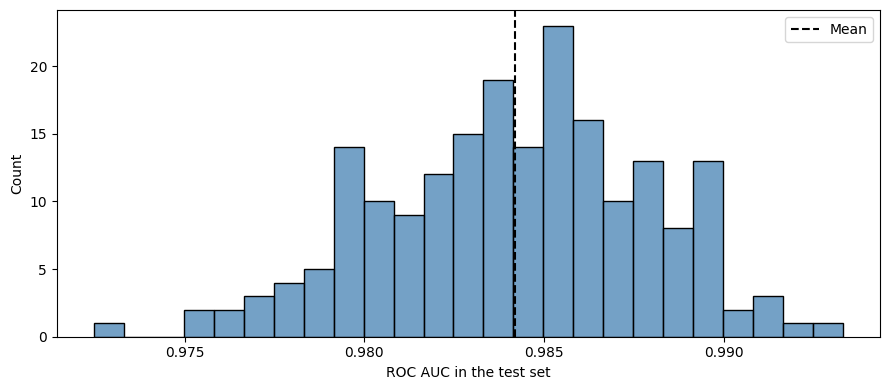

In [46]:
#Chart of the Variability of a Single Split
plt.figure(figsize=(9, 4))
sns.histplot(aucs, bins=25, color='steelblue')
plt.axvline(aucs.mean(), color='black', linestyle='--', label='Mean')
plt.xlabel('ROC AUC in the test set')
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
#Choose the Size of the Test Set ( Small Test = Noisy Estimate / Small Train = Pessimistic Estimate )
rows = []
for test_size in [0.10, 0.20, 0.30, 0.40, 0.50]:
    scores = []
    for seed in range(30):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=seed, stratify=y)
        scores.append(roc_auc_score(y_te, make_model().fit(X_tr, y_tr).predict_proba(X_te)[:, 1]))
    rows.append({'test_size': test_size, 'train_rows': int(len(X) * (1 - test_size)), 'positives_in_test': int(len(X) * test_size * y.mean()),
                 'AUC_mean': np.mean(scores), 'AUC_std': np.std(scores, ddof=1)})
test_size_table = pd.DataFrame(rows).set_index('test_size')
test_size_table.round(4)

,train_rows,positives_in_test,AUC_mean,AUC_std
test_size,,,,
0.1,1800,28,0.9829,0.0047
0.2,1600,56,0.9833,0.0028
0.3,1400,84,0.9832,0.0030
0.4,1200,113,0.9834,0.0027
0.5,1000,141,0.9833,0.0017


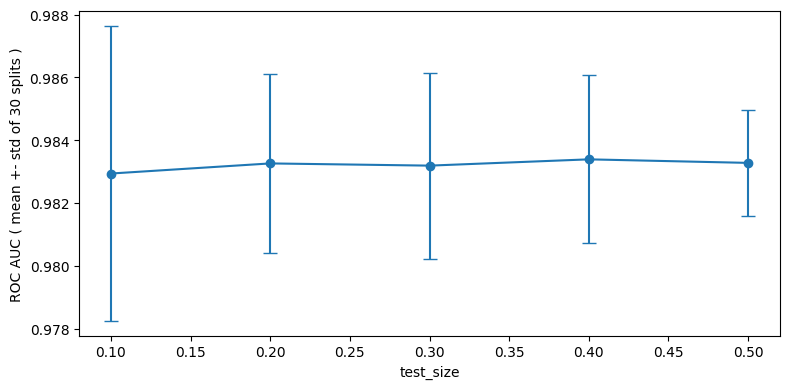

In [48]:
#Chart of the Size of the Test Set ( Mean +- Standard Deviation of the AUC )
plt.figure(figsize=(8, 4))
plt.errorbar(test_size_table.index, test_size_table['AUC_mean'], yerr=test_size_table['AUC_std'], fmt='o-', capsize=5)
plt.xlabel('test_size')
plt.ylabel('ROC AUC ( mean +- std of 30 splits )')
plt.tight_layout()
plt.show()

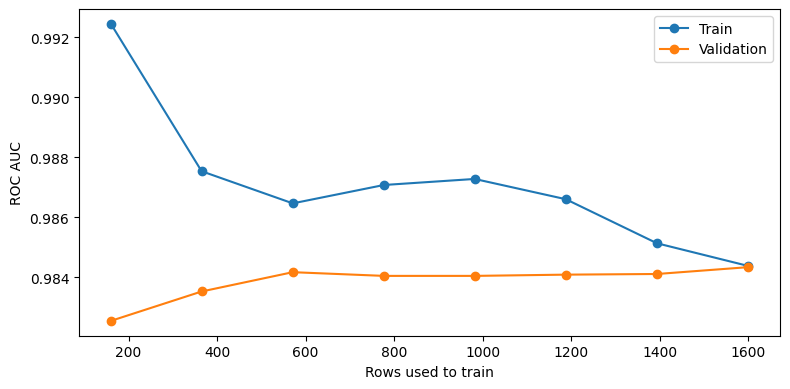

Gap train - validation with all the data: 0.0
Improvement of the last step: 0.0002


In [49]:
#Learning Curve ( Does the Model Need More Data? )
train_sizes, train_scores, val_scores = learning_curve(make_model(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                                                       scoring='roc_auc', train_sizes=np.linspace(0.1, 1.0, 8))
plt.figure(figsize=(8, 4))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation')
plt.xlabel('Rows used to train')
plt.ylabel('ROC AUC')
plt.legend()
plt.tight_layout()
plt.show()

#Metrics ( Gap Between Train and Validation = Overfitting / Improvement of the Last Step = Is More Data Useful? )
print('Gap train - validation with all the data:', round(train_scores.mean(axis=1)[-1] - val_scores.mean(axis=1)[-1], 4))
print('Improvement of the last step:', round(val_scores.mean(axis=1)[-1] - val_scores.mean(axis=1)[-2], 4))

In [50]:
#Compare the Cross-Validation Strategies ( Same Model, Same Data )
def compare_cv(strategies, scoring='roc_auc'):
    rows = []
    for name, cv in strategies.items():
        start = time.time()
        scores = cross_val_score(make_model(), X, y, cv=cv, scoring=scoring, groups=groups if name in group_strategies else None)
        n = len(scores)
        rows.append({'strategy': name, 'n_splits': n, 'mean': scores.mean(), 'std': scores.std(ddof=1), 'ci95_half_width': 1.96 * scores.std(ddof=1) / np.sqrt(n), 'time_s': time.time() - start})
    return pd.DataFrame(rows).set_index('strategy')

comparison = compare_cv(strategies)
comparison.round(4)

,n_splits,mean,std,ci95_half_width,time_s
strategy,,,,,
KFold (5),5,0.9841,0.0073,0.0064,0.1374
StratifiedKFold (5),5,0.9843,0.0044,0.0038,0.1982
RepeatedStratifiedKFold (5x3),15,0.9839,0.0054,0.0028,0.3105
ShuffleSplit (10 x 25%),10,0.9824,0.0036,0.0022,0.1824
StratifiedShuffleSplit (10 x 25%),10,0.9829,0.0048,0.0030,0.1941
StratifiedGroupKFold (5),5,0.9841,0.0030,0.0026,0.3771
TimeSeriesSplit (5),5,0.9841,0.0042,0.0037,0.0913


In [51]:
#Several Metrics at Once ( cross_validate: Mean and Standard Deviation of Each Metric )
scoring = ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']
cv_results = cross_validate(make_model(), X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0), scoring=scoring, return_train_score=True)
pd.DataFrame({'test_mean': {m: cv_results[f'test_{m}'].mean() for m in scoring},
              'test_std': {m: cv_results[f'test_{m}'].std(ddof=1) for m in scoring},
              'train_mean': {m: cv_results[f'train_{m}'].mean() for m in scoring}}).round(4)

,test_mean,test_std,train_mean
accuracy,0.9470,0.0097,0.9485
balanced_accuracy,0.8763,0.0266,0.8793
precision,0.8386,0.0493,0.8423
recall,0.7776,0.0541,0.7827
f1,0.8056,0.0380,0.8113
roc_auc,0.9843,0.0044,0.9844
average_precision,0.9169,0.0243,0.9165


In [52]:
#Stability Study ( Each Strategy Repeated with 10 Different Seeds: How Much Does the Estimate Change? )
factories = {'Hold-out 75/25 (stratified)': lambda seed: StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=seed),
             'Hold-out 50/50 (stratified)': lambda seed: StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=seed),
             'KFold (5)': lambda seed: KFold(n_splits=5, shuffle=True, random_state=seed),
             'StratifiedKFold (5)': lambda seed: StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
             'StratifiedKFold (10)': lambda seed: StratifiedKFold(n_splits=10, shuffle=True, random_state=seed),
             'RepeatedStratifiedKFold (5x3)': lambda seed: RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed),
             'StratifiedShuffleSplit (20 x 25%)': lambda seed: StratifiedShuffleSplit(n_splits=20, test_size=0.25, random_state=seed)}

# The reference is the best estimate we can get: 10 repetitions of a 5-fold stratified cross-validation
reference = cross_val_score(make_model(), X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=99), scoring='roc_auc').mean()

rows = []
for name, factory in factories.items():
    start = time.time()
    estimates, fits = [], 0
    for seed in range(10):
        scores = cross_val_score(make_model(), X, y, cv=factory(seed), scoring='roc_auc')
        estimates.append(scores.mean())
        fits += len(scores)
    rows.append({'strategy': name, 'models_per_estimate': fits / 10, 'mean_estimate': np.mean(estimates), 'bias_vs_reference': np.mean(estimates) - reference,
                 'std_of_estimates': np.std(estimates, ddof=1), 'time_s': time.time() - start})
stability = pd.DataFrame(rows).set_index('strategy')
print('Reference AUC ( best estimate ):', round(reference, 4))
stability.round(4)

Reference AUC ( best estimate ): 0.9839


,models_per_estimate,mean_estimate,bias_vs_reference,std_of_estimates,time_s
strategy,,,,,
Hold-out 75/25 (stratified),1.0,0.9842,0.0003,0.0033,0.2423
Hold-out 50/50 (stratified),1.0,0.9831,-0.0008,0.0016,0.2112
KFold (5),5.0,0.9842,0.0003,0.0003,0.9304
StratifiedKFold (5),5.0,0.9841,0.0002,0.0004,1.1054
StratifiedKFold (10),10.0,0.9840,0.0001,0.0004,1.8816
RepeatedStratifiedKFold (5x3),15.0,0.9840,0.0001,0.0001,2.9065
StratifiedShuffleSplit (20 x 25%),20.0,0.9837,-0.0002,0.0005,6.7749


In [53]:
#Nested Cross-Validation ( The Score of the Best Parameters Chosen on the SAME Data is Optimistic )
param_grid = {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
search = GridSearchCV(make_model(), param_grid, cv=inner_cv, scoring='roc_auc')

#Metrics ( Non-Nested = Score Used to Choose the Parameters / Nested = Honest Estimate )
non_nested = search.fit(X, y).best_score_
nested = cross_val_score(search, X, y, cv=outer_cv, scoring='roc_auc').mean()
print('Non-nested AUC:', round(non_nested, 4), '| Nested AUC:', round(nested, 4), '| Optimism:', round(non_nested - nested, 4))

Non-nested AUC: 0.9845 | Nested AUC: 0.9846 | Optimism: -0.0


In [54]:
#Leakage Check ( Scaler Fitted on ALL the Data vs Only on the Train Data )
X_filled = X.fillna(X.median())
X_tr, X_te, y_tr, y_te = train_test_split(X_filled, y, test_size=0.25, random_state=0, stratify=y)
scaler_leak = StandardScaler().fit(X_filled)           # Sees the test rows
scaler_ok = StandardScaler().fit(X_tr)                 # Sees only the train rows
print(pd.DataFrame({'leaky ( fit on all )': scaler_leak.transform(X_te).mean(axis=0), 'correct ( fit on train )': scaler_ok.transform(X_te).mean(axis=0)}, index=X.columns).round(4))

#Metrics ( The Difference Between the Two Scores is the Optimism Created by the Leakage )
# Attention! A simple scaler creates a small leakage. Feature selection, target encoding or imputation using the target, fitted BEFORE the split, can create a huge one
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
auc_leak = cross_val_score(LogisticRegression(max_iter=1000), StandardScaler().fit_transform(X_filled), y, cv=cv, scoring='roc_auc').mean()
auc_ok = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_filled, y, cv=cv, scoring='roc_auc').mean()
print('\nAUC with leakage:', round(auc_leak, 4), '| AUC without leakage ( Pipeline ):', round(auc_ok, 4), '| Difference:', round(auc_leak - auc_ok, 4))

        leaky ( fit on all )  correct ( fit on train )
income               -0.0142                   -0.0190
age                  -0.0091                   -0.0124
loan                 -0.0116                   -0.0155

AUC with leakage: 0.9844 | AUC without leakage ( Pipeline ): 0.9843 | Difference: 0.0


### **09. How to Choose the Best Way to Split**

| Situation | Recommended split |
|---|---|
| Large dataset ( hundreds of thousands of rows ) | Hold-out ( train / validation / test ), stratified for classification |
| Medium dataset, classification | `StratifiedKFold` ( 5 or 10 folds ) |
| Small dataset or rare classes | `RepeatedStratifiedKFold` ( 5 x 3 or 5 x 10 ) |
| Several rows of the same entity | `GroupKFold` or `StratifiedGroupKFold` |
| Data with time order | `TimeSeriesSplit` or ordered hold-out ( `shuffle=False` ) |
| Choosing parameters AND estimating the final score | Nested cross-validation |
| Estimate the uncertainty of the score | Bootstrap or repeated cross-validation |

**Always check:** the class proportion in train and test, the similarity between them ( KS, SMD, PSI, adversarial AUC ), the overlap of groups and duplicated rows, the **stability** of the estimate ( standard deviation across seeds ) and that every transformation is fitted **only on the train data**.

In [55]:
#Create the Function that Recommends a Split
def recommend_split(n_rows, minority_share=None, has_groups=False, is_time_ordered=False, min_minority_in_test=50):
    reasons = []
    if is_time_ordered:
        choice = 'TimeSeriesSplit ( or ordered hold-out with shuffle=False )'
        reasons.append('the rows have a time order: the train must come before the test')
    elif has_groups:
        choice = 'StratifiedGroupKFold' if minority_share is not None and minority_share < 0.30 else 'GroupKFold'
        reasons.append('rows of the same entity must stay together')
    elif n_rows >= 100_000:
        choice = 'Hold-out ( train / validation / test )'
        reasons.append('with a lot of data a single split is stable and cheap')
    elif n_rows >= 5_000:
        choice = 'StratifiedKFold ( 5 or 10 folds )'
        reasons.append('medium dataset: cross-validation uses all the rows')
    else:
        choice = 'RepeatedStratifiedKFold ( 5 x 3 or 5 x 10 )'
        reasons.append('small dataset: repeating the cross-validation reduces the variance of the estimate')
    if minority_share is not None:
        needed = min_minority_in_test / minority_share
        reasons.append(f'rare class ( {minority_share * 100:.1f}% ): use stratification and a test set with at least {needed:.0f} rows ( {needed / n_rows * 100:.0f}% of the data ) to have {min_minority_in_test} rare cases')
    print('Recommended:', choice)
    for reason in reasons:
        print(' -', reason)

recommend_split(n_rows=len(X), minority_share=y.mean())

Recommended: RepeatedStratifiedKFold ( 5 x 3 or 5 x 10 )
 - small dataset: repeating the cross-validation reduces the variance of the estimate
 - rare class ( 14.1% ): use stratification and a test set with at least 353 rows ( 18% of the data ) to have 50 rare cases


In [56]:
#Choose Based on the Stability Study ( Smallest Variation Among the Strategies with Small Bias )
acceptable = stability[stability['bias_vs_reference'].abs() < 0.01]
best_strategy = acceptable.sort_values(['std_of_estimates', 'time_s']).index[0]
print('Best strategy of the study:', best_strategy)
acceptable.sort_values(['std_of_estimates', 'time_s']).round(4)

Best strategy of the study: RepeatedStratifiedKFold (5x3)


,models_per_estimate,mean_estimate,bias_vs_reference,std_of_estimates,time_s
strategy,,,,,
RepeatedStratifiedKFold (5x3),15.0,0.9840,0.0001,0.0001,2.9065
KFold (5),5.0,0.9842,0.0003,0.0003,0.9304
StratifiedKFold (5),5.0,0.9841,0.0002,0.0004,1.1054
StratifiedKFold (10),10.0,0.9840,0.0001,0.0004,1.8816
StratifiedShuffleSplit (20 x 25%),20.0,0.9837,-0.0002,0.0005,6.7749
Hold-out 50/50 (stratified),1.0,0.9831,-0.0008,0.0016,0.2112
Hold-out 75/25 (stratified),1.0,0.9842,0.0003,0.0033,0.2423


In [57]:
#Apply the Chosen Split ( Final Hold-out: 80% Train and 20% Test, Stratified )
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0, stratify=y)

#Metrics ( Quality of the Final Split )
pd.DataFrame([split_report(X_train, X_test, y_train, y_test, 'Final split')]).round(3).T

,Final split
train_rows,1600
test_rows,400
test_%,20.0
positive_%_train,14.125
positive_%_test,14.25
class_gap_pp,0.125
class_chi2_pvalue,1.0
KS_max,0.048
KS_min_pvalue,0.443
SMD_max,0.016


In [58]:
#Save the Train and Test Files
train = X_train.assign(result=y_train)
test = X_test.assign(result=y_test)
train.to_csv('credit_data_train.csv', index=False)
test.to_csv('credit_data_test.csv', index=False)
print(train.shape, test.shape)

#Download the Files ( Google Colab )
# from google.colab import files
# files.download('credit_data_train.csv')
# files.download('credit_data_test.csv')

(1600, 4) (400, 4)
